<a href="https://colab.research.google.com/github/ZukhrufianAbdullah/PCVK_Ganjil_2026/blob/main/Week-08/Week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 — Segmentasi Citra dengan Thresholding
**Mata kuliah:** Pengolahan Citra dan Visi Komputer (RTI245007) · **Modul P7 — D1. Tugas Individu & D2. Tugas Kelompok**



## 0. Persiapan

**Langkah 1 — Hubungkan Colab dengan Drive.**

In [19]:
# Mount Google Drive (dilewati otomatis jika dijalankan di luar Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Bukan di Colab: mount Drive dilewati.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Langkah 2 — Import library.**

In [20]:
#Library yang digunakan
import os, re, math, difflib, shutil, subprocess, sys
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans

try:
    from google.colab.patches import cv2_imshow
except ImportError:
    cv2_imshow = None

plt.rcParams['figure.dpi'] = 100
print('OpenCV', cv.__version__)

OpenCV 5.0.0


**Langkah 3 — Isi path gambar**


In [21]:
PATH_GRADIENT = '/content/drive/MyDrive/PCVK/Gambar/gradient.jpg'
PATH_SUDOKU   = '/content/drive/MyDrive/PCVK/Gambar/sudoku-original.jpg'
PATH_LENA     = '/content/drive/MyDrive/PCVK/Gambar/lena_gs_lc2.jpg'
PATH_KTP      = '/content/drive/MyDrive/PCVK/Gambar/ktp_fulan.jpg'

---
## 3. Global Threshold manual (T = 200)

Aturan (dengan `maxval = 255`):

| Jenis | Jika piksel > thresh | Jika piksel ≤ thresh |
|---|---|---|
| BINARY | Menjadi nilai maksimal | Menjadi 0 |
| BINARY_INV | Menjadi 0 | Menjadi nilai maksimal |
| TRUNC | Menjadi thresh | nilai asli tetap |
| TOZERO | nilai asli tetap | Menjadi 0 |
| TOZERO_INV | Menjadi 0 | nilai asli tetap |

Semuanya diimplementasikan dengan operasi NumPy (`np.where`) tanpa `cv.threshold()`.

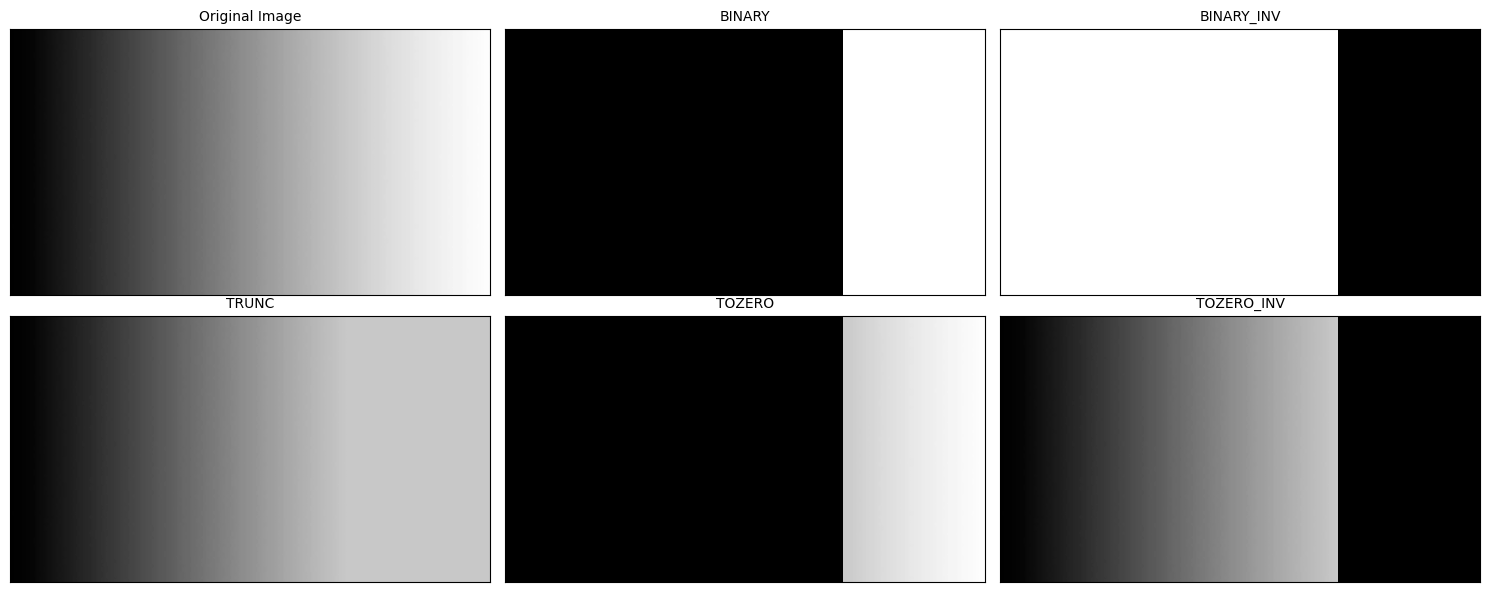

BINARY      identik dengan cv.threshold: True
BINARY_INV  identik dengan cv.threshold: True
TRUNC       identik dengan cv.threshold: True
TOZERO      identik dengan cv.threshold: True
TOZERO_INV  identik dengan cv.threshold: True


In [22]:
def global_threshold_manual(img, thresh, maxval, jenis):
    img = img.astype(np.uint8)
    atas = img > thresh                      # mask: piksel di atas ambang
    if jenis == 'BINARY':
        out = np.where(atas, maxval, 0)
    elif jenis == 'BINARY_INV':
        out = np.where(atas, 0, maxval)
    elif jenis == 'TRUNC':
        out = np.where(atas, thresh, img)
    elif jenis == 'TOZERO':
        out = np.where(atas, img, 0)
    elif jenis == 'TOZERO_INV':
        out = np.where(atas, 0, img)
    else:
        raise ValueError(jenis)
    return out.astype(np.uint8)

# citra gradasi hitam -> putih
img = cv.imread(path_gambar('gradient.jpg'), cv.IMREAD_GRAYSCALE)
thresh, maxval = 200, 255

jenis_list = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
hasil = [global_threshold_manual(img, thresh, maxval, j) for j in jenis_list]

fig, axs = plt.subplots(2, 3, figsize=(15, 6))
for ax, im, jd in zip(axs.ravel(), [img] + hasil, ['Original Image'] + jenis_list):
    tampil(ax, im, jd)
plt.tight_layout(); plt.show()

# verifikasi terhadap OpenCV (hanya untuk membandingkan, bukan dipakai pada hasil)
tipe_cv = [cv.THRESH_BINARY, cv.THRESH_BINARY_INV, cv.THRESH_TRUNC, cv.THRESH_TOZERO, cv.THRESH_TOZERO_INV]
for j, t, h in zip(jenis_list, tipe_cv, hasil):
    _, ref = cv.threshold(img, thresh, maxval, t)
    print(f'{j:11s} identik dengan cv.threshold: {np.array_equal(h, ref)}')

---
## 4. Adaptive Threshold manual (Mean & Gaussian)

Ambang tiap piksel: **T(x,y) = rata-rata lokal − C**, lalu piksel menjadi putih bila `I(x,y) > T(x,y)`.

Syarat tugas: tanpa `cv.threshold()`, `cv.adaptiveThreshold()`, maupun filter siap pakai.
Rata-rata lokal dihitung sendiri dengan **konvolusi terpisah (separable)** memakai irisan array NumPy:
- *Mean*: kernel 1D seragam `[1/11, …, 1/11]`
- *Gaussian*: kernel 1D Gaussian ukuran 11 dengan σ = 2, dinormalkan

Tepi citra diperlakukan dengan replikasi piksel tepi (`np.pad(mode='edge')`).

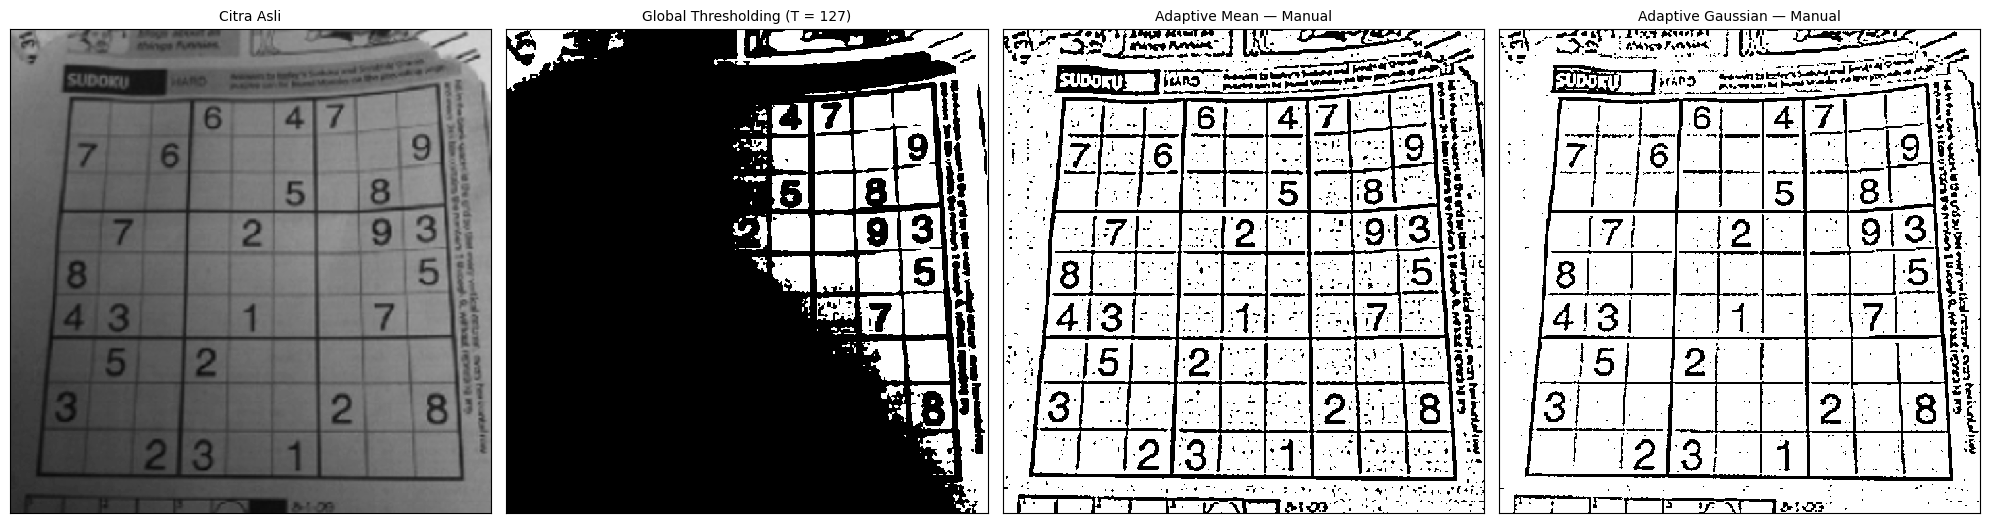

Kemiripan piksel Mean     vs OpenCV: 97.42%
Kemiripan piksel Gaussian vs OpenCV: 97.99%


In [23]:
def kernel_seragam(n):
    return np.ones(n) / n

def kernel_gaussian(n, sigma):
    r = n // 2
    x = np.arange(-r, r + 1)
    k = np.exp(-(x ** 2) / (2 * sigma ** 2))
    return k / k.sum()

def rata_rata_lokal(gray, k1d):
    # konvolusi 2D terpisah: baris lalu kolom (kernel simetris -> korelasi = konvolusi)
    r = len(k1d) // 2
    H, W = gray.shape
    p = np.pad(gray.astype(np.float64), r, mode='edge')
    tmp = np.zeros((H + 2*r, W))
    for i, w in enumerate(k1d):              # arah horizontal
        tmp += w * p[:, i:i + W]
    out = np.zeros((H, W))
    for i, w in enumerate(k1d):              # arah vertikal
        out += w * tmp[i:i + H, :]
    return out

def adaptive_manual(gray, metode='mean', ukuran=11, C=2, sigma=2):
    k = kernel_seragam(ukuran) if metode == 'mean' else kernel_gaussian(ukuran, sigma)
    T = rata_rata_lokal(gray, k) - C         # ambang lokal T(x,y)
    return np.where(gray > T, 255, 0).astype(np.uint8)

gray = cv.imread(path_gambar('sudoku-original.jpg'), cv.IMREAD_GRAYSCALE)

th_global = global_threshold_manual(gray, 127, 255, 'BINARY')          # global manual, T = 127
th_mean   = adaptive_manual(gray, 'mean', ukuran=11, C=2)
th_gauss  = adaptive_manual(gray, 'gaussian', ukuran=11, C=2, sigma=2)

fig, axs = plt.subplots(1, 4, figsize=(20, 6))
for ax, im, jd in zip(axs, [gray, th_global, th_mean, th_gauss],
                      ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']):
    tampil(ax, im, jd)
plt.tight_layout(); plt.show()

# verifikasi terhadap OpenCV (pembanding saja)
ref_m = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)
ref_g = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
print(f'Kemiripan piksel Mean     vs OpenCV: {(th_mean == ref_m).mean()*100:.2f}%')
print(f'Kemiripan piksel Gaussian vs OpenCV: {(th_gauss == ref_g).mean()*100:.2f}%')

**Pengamatan.** Threshold global (T = 127) gagal: sisi gelap citra seluruhnya hitam karena semua pikselnya (termasuk kertas) ≤ 127.
Adaptive threshold membandingkan piksel dengan lingkungannya sendiri, sehingga angka dan garis di area gelap tetap terbaca.
Versi Gaussian memberi bobot lebih besar pada piksel dekat pusat jendela sehingga lebih sedikit bintik noise daripada versi Mean.
(Selisih kecil dengan OpenCV wajar karena OpenCV membulatkan rata-rata lokal ke bilangan bulat.)

---
## 5. Otsu Thresholding manual

Untuk tiap kandidat T (0…254), piksel dibagi menjadi kelas 0 (intensitas ≤ T) dan kelas 1 (intensitas > T).
Dipilih T yang **memaksimalkan between-class variance** (setara meminimalkan within-class variance):

$$\sigma_B^2(T)=\frac{\left(\mu_T\,\omega_0(T)-\mu(T)\right)^2}{\omega_0(T)\,\bigl(1-\omega_0(T)\bigr)}$$

dengan ω₀(T) = probabilitas kumulatif, μ(T) = rata-rata kumulatif, dan μ_T = rata-rata seluruh citra.
Seluruh kandidat dihitung sekaligus dengan `np.cumsum`.

In [24]:
def otsu_manual(gray):
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()                        # p(i)
    omega = np.cumsum(p)                         # w0(T): kelas intensitas <= T
    mu = np.cumsum(np.arange(256) * p)           # mean kumulatif
    mu_T = mu[-1]                                # mean seluruh citra
    sigma_b = np.zeros(256)
    sah = (omega > 0) & (omega < 1)              # hindari pembagian dengan nol
    sigma_b[sah] = (mu_T * omega[sah] - mu[sah]) ** 2 / (omega[sah] * (1 - omega[sah]))
    T = int(np.argmax(sigma_b))
    biner = np.where(gray > T, 255, 0).astype(np.uint8)
    return biner, T, sigma_b

# --- Pembuktian dengan contoh 6x6 pada modul (histogram: jumlah piksel nilai 0..5 = 8,7,2,6,9,4)
h6 = np.array([8, 7, 2, 6, 9, 4], float); N6 = h6.sum(); v = np.arange(6)
baris = []
for t in range(6):                               # konvensi modul: background = nilai < t
    wb, wf = h6[:t].sum()/N6, h6[t:].sum()/N6
    mb = (v[:t]*h6[:t]).sum()/h6[:t].sum() if wb > 0 else 0
    mf = (v[t:]*h6[t:]).sum()/h6[t:].sum()
    vb = ((v[:t]-mb)**2*h6[:t]).sum()/h6[:t].sum() if wb > 0 else 0
    vf = ((v[t:]-mf)**2*h6[t:]).sum()/h6[t:].sum()
    sw = wb*vb + wf*vf
    baris.append([t, round(wb,4), round(wf,4), round(sw,4), round(wb*wf*(mb-mf)**2,4)])
tabel6 = pd.DataFrame(baris, columns=['T', 'Wb', 'Wf', 'Within-class var', 'Between-class var'])
display(tabel6) if 'display' in globals() else print(tabel6)
print('T terbaik (within terkecil) =', int(tabel6.loc[tabel6['Within-class var'].idxmin(), 'T']),
      '| T terbaik (between terbesar) =', int(tabel6.loc[tabel6['Between-class var'].idxmax(), 'T']))

   T      Wb      Wf  Within-class var  Between-class var
0  0  0.0000  1.0000            3.1196             0.0000
1  1  0.2222  0.7778            1.5268             1.5928
2  2  0.4167  0.5833            0.5561             2.5635
3  3  0.4722  0.5278            0.4909             2.6287
4  4  0.6389  0.3611            0.9779             2.1417
5  5  0.8889  0.1111            2.2491             0.8705
T terbaik (within terkecil) = 3 | T terbaik (between terbesar) = 3


### 5A. Otsu manual vs library pada `lena_gs_lc2.jpg`

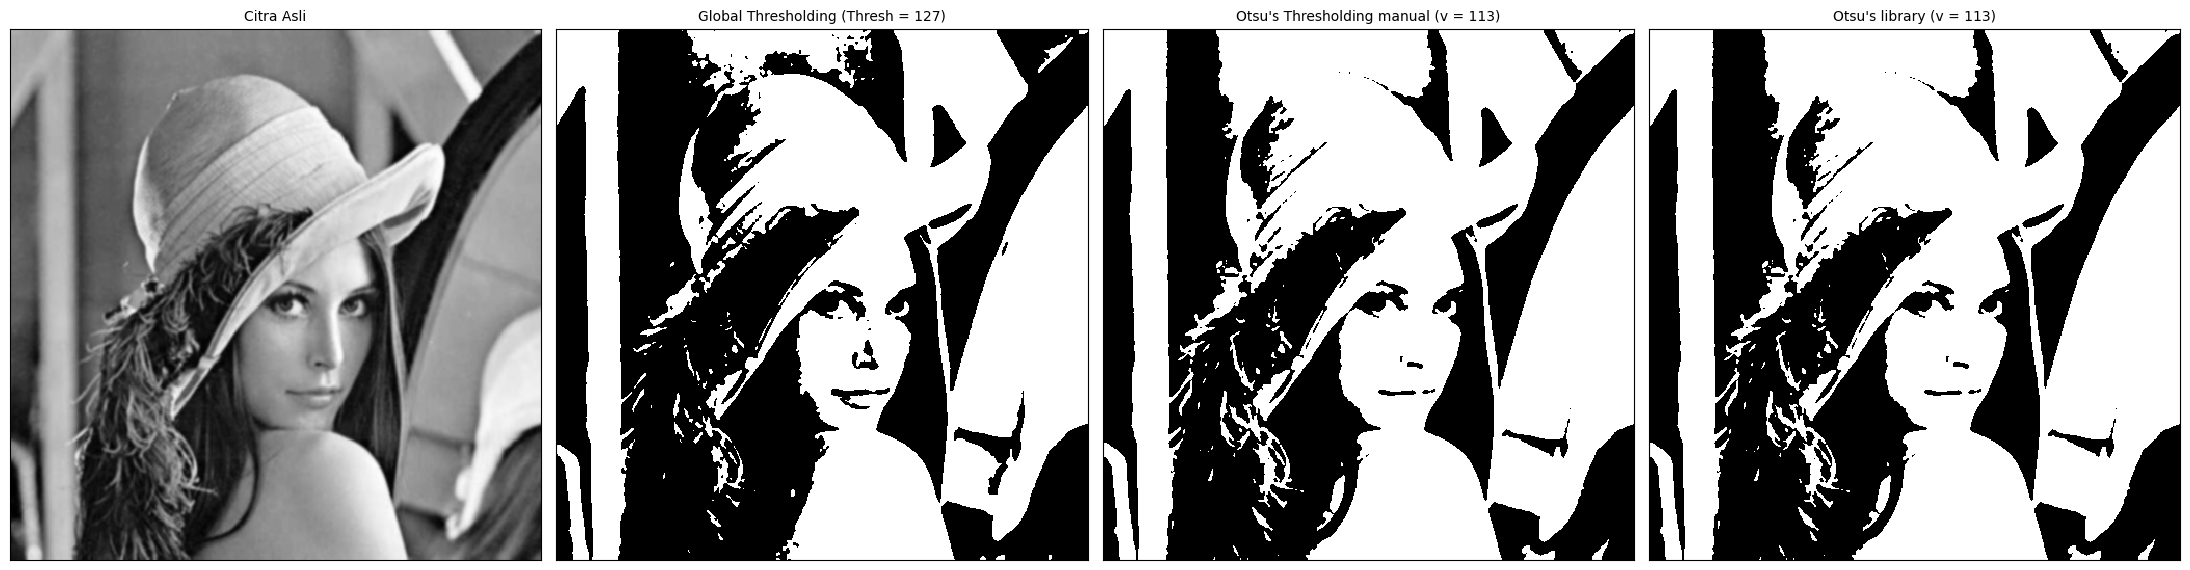

Threshold Otsu manual  : 113
Threshold Otsu library : 113
Hasil biner identik    : True


In [25]:
filename = path_gambar('lena_gs_lc2.jpg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh, sigma_b = otsu_manual(blur)
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
ret_lib, th_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

x = "Otsu's Thresholding manual (v = " + str(otsu_thresh) + ")"
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x, f"Otsu's library (v = {int(ret_lib)})"]
citra3 = [blur, th1, otsu_biner, th_lib]

fig, axs = plt.subplots(1, 4, figsize=(22, 6))
for ax, im, jd in zip(axs, citra3, titles):
    tampil(ax, im, jd)
plt.tight_layout(); plt.show()

print('Threshold Otsu manual  :', otsu_thresh)
print('Threshold Otsu library :', int(ret_lib))
print('Hasil biner identik    :', np.array_equal(otsu_biner, th_lib))

### Pertanyaan: mengapa Binary Thresholding (T = 127) hitam semua, dan berapa T agar Lena masih terlihat?

Rentang intensitas citra: 0 .. 254   (hanya 255 level dari 256)
Piksel > 127 : 132769 buah  -> semuanya <= 127, sehingga g(x,y) = 0 di mana-mana


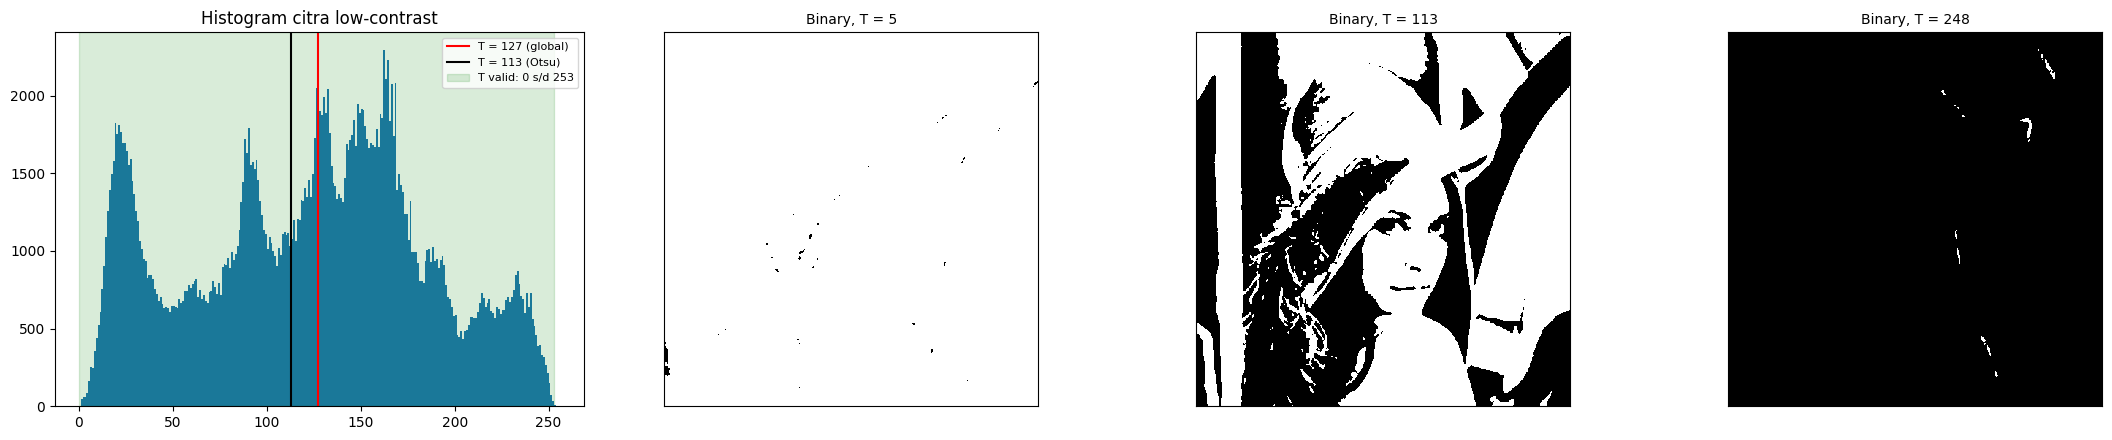

In [26]:
lo, hi = int(blur.min()), int(blur.max())
print(f'Rentang intensitas citra: {lo} .. {hi}   (hanya {hi - lo + 1} level dari 256)')
print(f'Piksel > 127 : {(blur > 127).sum()} buah  -> semuanya <= 127, sehingga g(x,y) = 0 di mana-mana')

fig, axs = plt.subplots(1, 4, figsize=(22, 4.5))
axs[0].hist(blur.ravel(), bins=256, range=(0, 256), color='tab:blue')
axs[0].axvline(127, color='red', label='T = 127 (global)')
axs[0].axvline(otsu_thresh, color='black', label=f'T = {otsu_thresh} (Otsu)')
axs[0].axvspan(lo, hi - 1, color='green', alpha=0.15, label=f'T valid: {lo} s/d {hi-1}')
axs[0].set_title('Histogram citra low-contrast'); axs[0].legend(fontsize=8)
for ax, T in zip(axs[1:], [lo + 5, otsu_thresh, hi - 6]):
    tampil(ax, global_threshold_manual(blur, T, 255, 'BINARY'), f'Binary, T = {T}')
plt.tight_layout(); plt.show()

**Jawaban.**

1. **Alasan hitam semua.** Citra Lena ini *low-contrast*: seluruh piksel hanya berada pada rentang sempit (± 85–108). Pada histogram, seluruh batang berada di **sebelah kiri garis T = 127**. Karena aturan BINARY adalah `g = 255` jika `f > T` dan `g = 0` jika `f ≤ T`, tidak ada satu piksel pun yang melewati 127, sehingga seluruh keluaran bernilai 0 (hitam). Satu kelas saja yang terbentuk, bukan dua.
2. **Ambang yang membuat Lena masih terlihat.** Ambang harus jatuh **di dalam rentang intensitas citra**, yaitu kira-kira **85 ≤ T < 108** (angka persis ditampilkan oleh sel di atas, `lo` s/d `hi−1`). Di luar rentang itu citra menjadi seluruhnya hitam (T ≥ maks) atau seluruhnya putih (T < min). Nilai yang paling baik adalah ambang hasil Otsu, **≈ 92–93**, karena memisahkan dua kelompok puncak histogram dengan between-class variance terbesar.
3. Pelajaran: T global harus dipilih dari **bentuk histogram**, bukan angka tetap (127). Otsu melakukan itu secara otomatis.

### 5B. Otsu vs Global threshold pada KTP

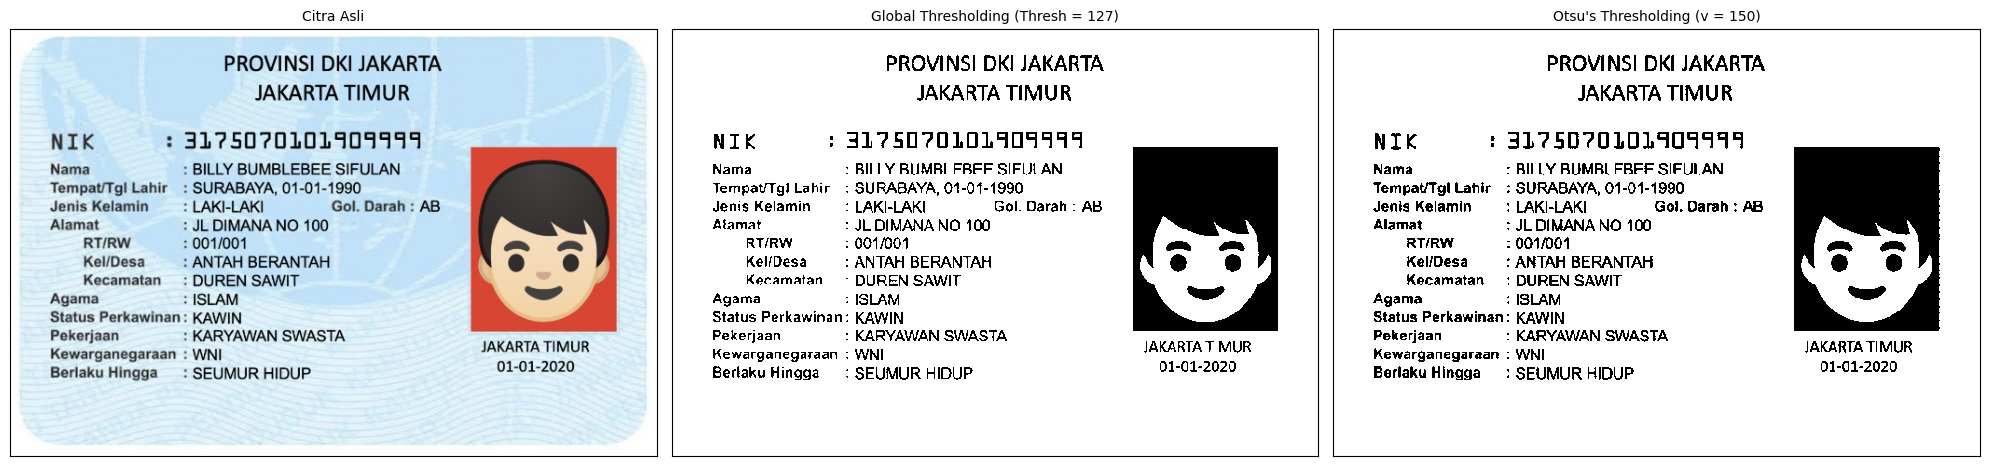

Threshold Otsu pada KTP : 150


In [27]:
ktp_bgr = cv.imread(path_gambar('ktp_fulan.jpg'))
ktp_gray = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2GRAY)

ktp_otsu, ktp_T, _ = otsu_manual(ktp_gray)
ktp_glob = global_threshold_manual(ktp_gray, 127, 255, 'BINARY')

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
tampil(axs[0], cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB), 'Citra Asli')
tampil(axs[1], ktp_glob, 'Global Thresholding (Thresh = 127)')
tampil(axs[2], ktp_otsu, f"Otsu's Thresholding (v = {ktp_T})")
plt.tight_layout(); plt.show()
print('Threshold Otsu pada KTP :', ktp_T)

**Perbandingan.** KTP memiliki latar biru muda yang terang. Pada T = 127 tetap, hampir seluruh latar (yang bernilai jauh di atas 127) menjadi putih sehingga ambang tidak peka terhadap kontras tulisan vs latar yang sebenarnya.
Otsu menaikkan ambangnya menyesuaikan histogram (nilainya ditampilkan di judul gambar), sehingga huruf yang lebih gelap dari latar terpisah lebih baik, sedangkan foto berwarna gelap/merah menjadi blok hitam.

---
## 6. Segmentasi Berbasis Region pada `data.coins()`

### 6A. Region Growing manual
Algoritma (sesuai pseudocode materi): mulai dari *seed*, tambahkan tetangga (8-ketetanggaan) bila
`|I(tetangga) − rata-rata region| ≤ T`, perbarui rata-rata region, ulangi sampai tidak ada piksel baru.

Tiga seed: **di dalam koin**, **di latar**, dan **tepat di tepi koin**. Nilai T = 5, 20, 60.

ukuran citra: (303, 384) uint8
Seed dalam koin    (baris, kolom) = (50, 43)  | intensitas = 175
Seed di latar      (baris, kolom) = (20, 100)  | intensitas = 115
Seed di tepi koin  (baris, kolom) = (33, 43)  | intensitas = 149


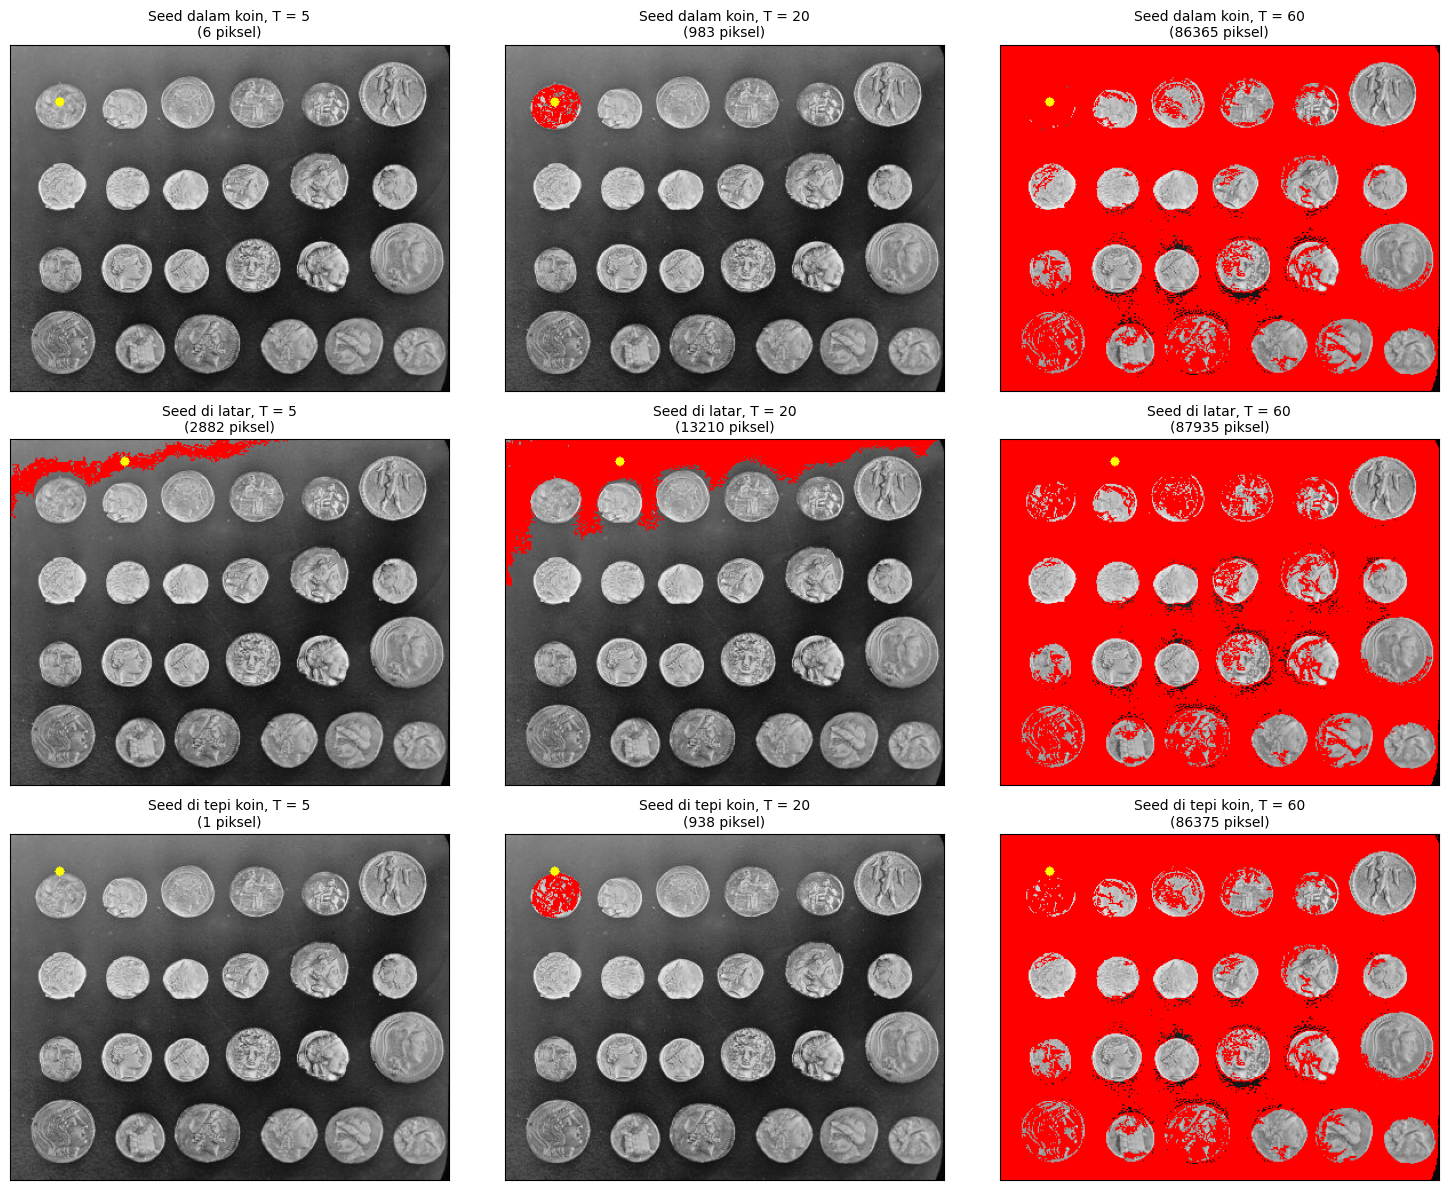

In [28]:
img = data.coins()                      # grayscale, 303 x 384
print('ukuran citra:', img.shape, img.dtype)

def region_growing(I, seed, T, hubungan=8):
    H, W = I.shape
    L = I.tolist()                                   # akses list Python lebih cepat daripada ndarray
    M = np.zeros((H, W), dtype=bool)
    if hubungan == 8:
        tetangga = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]
    else:
        tetangga = [(-1,0),(0,-1),(0,1),(1,0)]
    r0, c0 = seed
    M[r0, c0] = True
    rata, jumlah = float(L[r0][c0]), 1
    antrian = deque([(r0, c0)])
    while antrian:
        r, c = antrian.popleft()
        for dr, dc in tetangga:
            rr, cc = r + dr, c + dc
            if 0 <= rr < H and 0 <= cc < W and not M[rr, cc]:
                v = L[rr][cc]
                if abs(v - rata) <= T:                     # kriteria homogenitas
                    M[rr, cc] = True
                    antrian.append((rr, cc))
                    rata = (rata * jumlah + v) / (jumlah + 1)
                    jumlah += 1
    return M

SEEDS = {'Seed dalam koin': (50, 43),
         'Seed di latar':   (20, 100),
         'Seed di tepi koin': (33, 43)}
T_LIST = [5, 20, 60]

for nama, s in SEEDS.items():
    print(f'{nama:18s} (baris, kolom) = {s}  | intensitas = {img[s]}')

def overlay(I, M, warna=(255, 0, 0)):
    rgb = np.stack([I]*3, axis=-1).copy()
    rgb[M] = warna
    return rgb

hasil_A = {}
fig, axs = plt.subplots(3, 3, figsize=(15, 12))
for i, (nama, s) in enumerate(SEEDS.items()):
    for j, T in enumerate(T_LIST):
        M = region_growing(img, s, T)
        hasil_A[(nama, T)] = int(M.sum())
        ov = overlay(img, M)
        cv.circle(ov, (s[1], s[0]), 4, (255, 255, 0), -1)         # tandai seed (kuning)
        tampil(axs[i, j], ov, f'{nama}, T = {T}\n({M.sum()} piksel)')
plt.tight_layout(); plt.show()

**Pengamatan (6A).**
- **Seed dalam koin:** T = 5 hanya menghasilkan bercak sangat kecil (± 6 piksel) karena tekstur koin bervariasi; T = 20 menutupi hampir satu koin utuh (± 1000 piksel); T = 60 *bocor* ke latar lalu ke seluruh citra (± 86 ribu piksel), sehingga hanya bagian koin yang terang yang tersisa.
- **Seed di latar:** T = 5 hanya mengisi pita latar di bagian atas; T = 20 menyebar mengelilingi koin-koin baris atas; T = 60 menelan hampir seluruh citra.
- **Seed di tepi koin:** pada T = 5 region berhenti di 1 piksel karena tetangganya berselisih > 5 dari seed yang berada pada gradien; pada T = 20 hasilnya mirip seed dalam koin; pada T = 60 ikut bocor. Seed di tepi membuat hasil sangat bergantung pada T.
- Kesimpulan: Region Growing **sensitif terhadap posisi seed dan nilai T**; T terlalu kecil → region terlalu kecil (*over-segmentation*), T terlalu besar → kebocoran ke latar (*under-segmentation*). Nilai T ≈ 20 paling masuk akal untuk citra ini.

### 6B. `skimage.segmentation.flood()`
Fungsi ini menghasilkan mask region dari seed dengan menerima piksel yang **terhubung** dan intensitasnya berada dalam **toleransi terhadap intensitas seed** (bukan terhadap rata-rata region yang terus berubah).

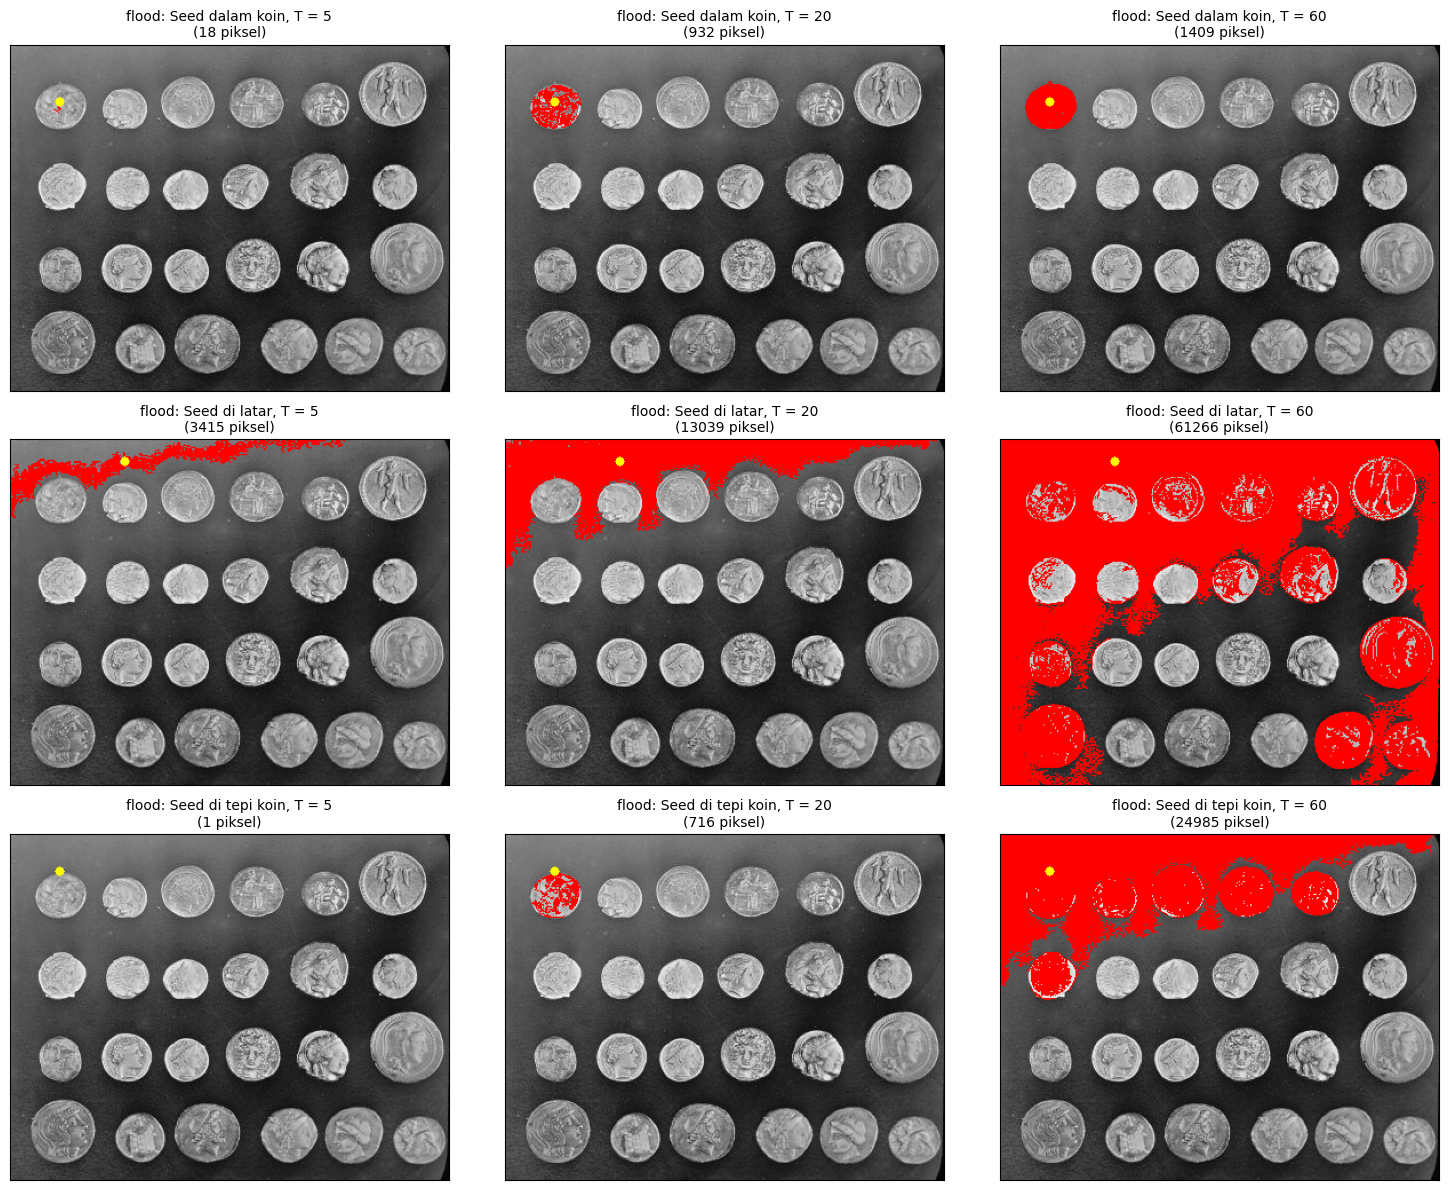

             Seed  T  Piksel (manual)  Piksel (flood)
  Seed dalam koin  5                6              18
  Seed dalam koin 20              983             932
  Seed dalam koin 60            86365            1409
    Seed di latar  5             2882            3415
    Seed di latar 20            13210           13039
    Seed di latar 60            87935           61266
Seed di tepi koin  5                1               1
Seed di tepi koin 20              938             716
Seed di tepi koin 60            86375           24985


In [29]:
gray = data.coins()
hasil_B = {}
fig, axs = plt.subplots(3, 3, figsize=(15, 12))
for i, (nama, s) in enumerate(SEEDS.items()):
    for j, T in enumerate(T_LIST):
        region = flood(gray, seed_point=s, tolerance=T, connectivity=2)    # 8 tetangga
        hasil_B[(nama, T)] = int(region.sum())
        ov = overlay(gray, region)
        cv.circle(ov, (s[1], s[0]), 4, (255, 255, 0), -1)
        tampil(axs[i, j], ov, f'flood: {nama}, T = {T}\n({region.sum()} piksel)')
plt.tight_layout(); plt.show()

# tabel perbandingan jumlah piksel manual vs flood
tab = pd.DataFrame([[n, T, hasil_A[(n, T)], hasil_B[(n, T)]] for n in SEEDS for T in T_LIST],
                   columns=['Seed', 'T', 'Piksel (manual)', 'Piksel (flood)'])
print(tab.to_string(index=False))

**Perbedaan manual vs `flood()`.** Keduanya sama-sama *connected* dan sama-sama bergantung pada seed & T. Perbedaannya pada acuan perbandingan:
manual membandingkan dengan **rata-rata region yang terus diperbarui** (bisa "merayap" ke intensitas lain), sedangkan `flood()` membandingkan dengan **intensitas seed yang tetap**
sehingga batas intensitasnya konsisten dan umumnya lebih terkendali; hasilnya berbeda terutama pada T besar. `flood()` juga jauh lebih cepat karena diimplementasikan dalam kode terkompilasi.

---
## 7. Segmentasi warna K-Means — tampilkan hanya warna biru pada KTP

Langkah: (1) baca KTP → RGB, (2) reshape menjadi vektor piksel, (3) K-Means (K = 8) pada ruang RGB,
(4) bentuk citra tersegmentasi dari pusat cluster, (5) ubah **pusat cluster** ke HSV dan pilih cluster yang memenuhi rentang biru:

`kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))` (skala HSV OpenCV: H 0–179, S/V 0–255),

(6) tampilkan hanya piksel milik cluster biru, sisanya dihitamkan.

Pusat cluster (RGB) dan HSV:
  cluster 0: RGB=(195, 224, 243)  HSV=(102, 50, 243) <-- biru
  cluster 1: RGB=(59, 61, 64)  HSV=(108, 20, 64) 
  cluster 2: RGB=(212, 70, 52)  HSV=(3, 192, 212) 
  cluster 3: RGB=(218, 238, 248)  HSV=(100, 31, 248) <-- biru
  cluster 4: RGB=(139, 149, 157)  HSV=(103, 29, 157) <-- biru
  cluster 5: RGB=(11, 18, 24)  HSV=(104, 138, 24) 
  cluster 6: RGB=(252, 253, 254)  HSV=(105, 2, 254) 
  cluster 7: RGB=(240, 210, 174)  HSV=(16, 70, 240) 


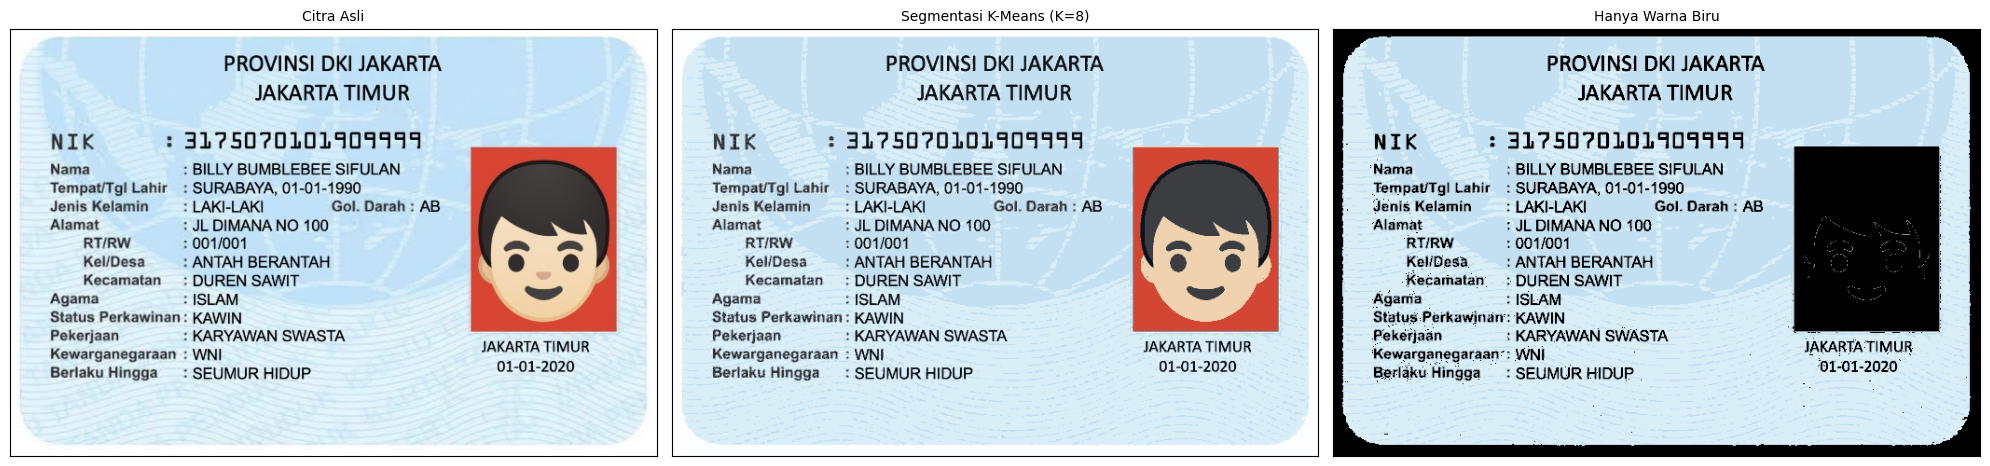

Piksel biru: 77.8% dari citra


In [30]:
img_bgr = cv.imread(path_gambar('ktp_fulan.jpg'))
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

K = 8
Z = np.float32(img_rgb.reshape((-1, 3)))
kmeans = KMeans(n_clusters=K, random_state=42, n_init=4)
labels = kmeans.fit_predict(Z)
centers = np.uint8(kmeans.cluster_centers_)

segmented_img = centers[labels].reshape(img_rgb.shape)

# pusat cluster -> HSV, lalu seleksi cluster biru
hsv_c = cv.cvtColor(centers.reshape(-1, 1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3)
H, S, V = hsv_c[:, 0], hsv_c[:, 1], hsv_c[:, 2]
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))[0]

print('Pusat cluster (RGB) dan HSV:')
for k in range(K):
    tanda = '<-- biru' if k in kelompok_biru else ''
    print(f'  cluster {k}: RGB={tuple(int(t) for t in centers[k])}  HSV={tuple(int(t) for t in hsv_c[k])} {tanda}')

mask_biru = np.isin(labels, kelompok_biru).reshape(img_rgb.shape[:2])
hanya_biru = np.zeros_like(segmented_img)
hanya_biru[mask_biru] = segmented_img[mask_biru]

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
tampil(axs[0], img_rgb, 'Citra Asli')
tampil(axs[1], segmented_img, f'Segmentasi K-Means (K={K})')
tampil(axs[2], hanya_biru, 'Hanya Warna Biru')
plt.tight_layout(); plt.show()
print(f'Piksel biru: {mask_biru.mean()*100:.1f}% dari citra')

**Catatan.** K-Means mengelompokkan piksel berdasarkan kemiripan warna tanpa memperhatikan posisi. Latar KTP berupa gradasi biru muda sehingga terbagi menjadi beberapa cluster biru yang berdekatan; semuanya terpilih oleh aturan HSV.
Area non-biru (misalnya foto merah) menjadi hitam. Cluster teks gelap (hasil rata-rata piksel huruf dan latar biru) juga memiliki hue biru sehingga ikut terpilih, tetapi nilainya sangat gelap sehingga tampak hampir hitam.
Rentang HSV dapat disesuaikan bila KTP Anda memiliki warna latar berbeda.

---
# D2. Tugas Kelompok — Perbandingan OCR pada Citra Berwarna vs Hasil Segmentasi

**Alur:** KTP berwarna → (grayscale) → Otsu / Adaptive → `pytesseract.image_to_string()` pada ketiganya dengan **bahasa dan `--psm` yang sama** →
kotak hijau dengan `image_to_data()` (confidence > 60) → tabel 10 item acuan → persentase kecocokan.

### D2.0 Instal Tesseract

In [31]:
if shutil.which('tesseract') is None:
    subprocess.run('apt-get -qq update && apt-get -qq install -y tesseract-ocr tesseract-ocr-ind', shell=True, check=False)
try:
    import pytesseract
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'pytesseract'], check=False)
    import pytesseract

tersedia = pytesseract.get_languages(config='')
print('Bahasa Tesseract tersedia:', tersedia)
LANG = 'ind' if 'ind' in tersedia else 'eng'      # bahasa yang SAMA untuk ketiga citra
PSM = 6                                            # --psm yang SAMA untuk ketiga citra
CONFIG = f'--psm {PSM}'
BATAS_CONF = 60
print('Memakai LANG =', LANG, '| CONFIG =', CONFIG)

Bahasa Tesseract tersedia: ['eng', 'osd']
Memakai LANG = eng | CONFIG = --psm 6


### D2.1 Siapkan tiga citra (ukuran sama)
Parameter thresholding (bisa disetel): Otsu setelah Gaussian blur ringan; Adaptive Gaussian dengan `blockSize = 31`, `C = 10`
(blok lebih besar dari tebal goresan huruf; C > 0 agar latar polos bersih).

{'Berwarna asli': (659, 1000, 3), 'Segmentasi Otsu': (659, 1000, 3), 'Segmentasi Adaptive': (659, 1000, 3)}


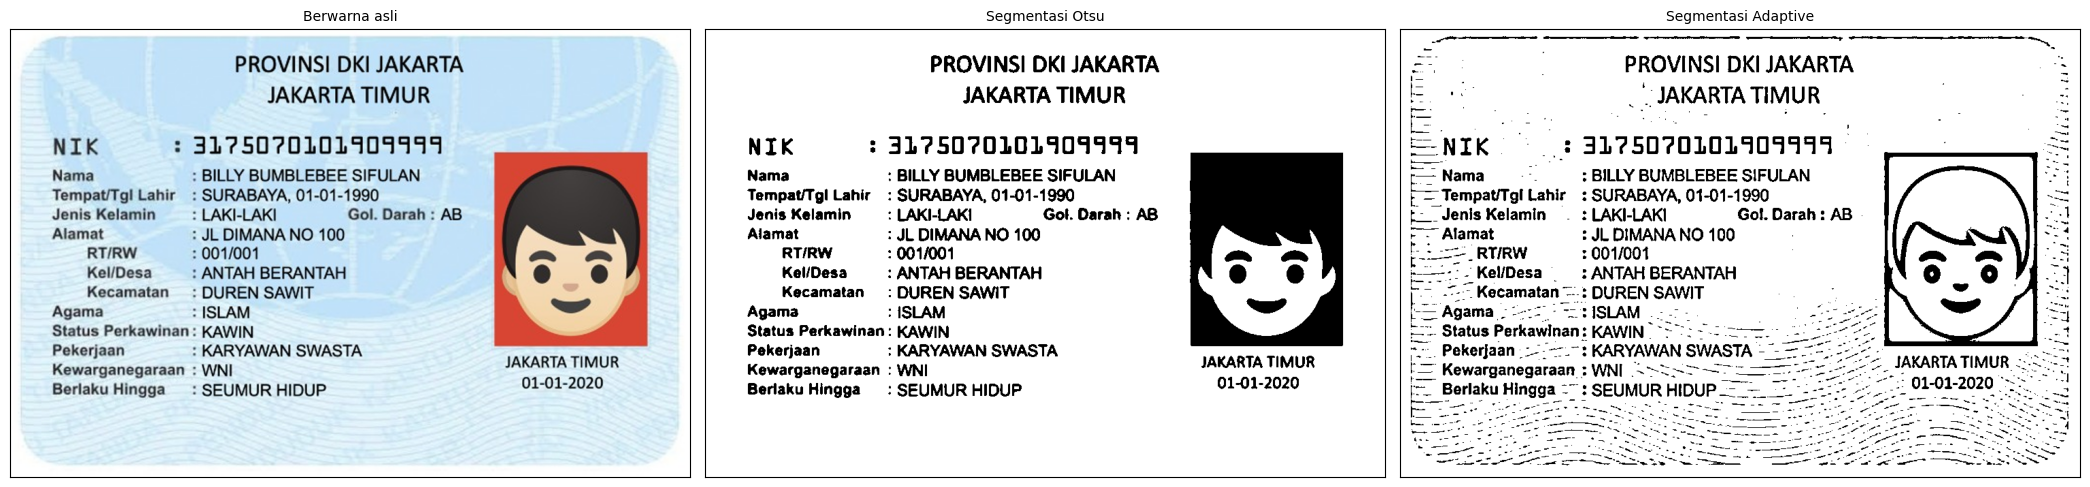

In [32]:
LEBAR = 1000                                                        # ukuran seragam untuk semua citra
ktp = cv.imread(path_gambar('ktp_fulan.jpg'))
skala = LEBAR / ktp.shape[1]
ktp = cv.resize(ktp, (LEBAR, int(ktp.shape[0] * skala)), interpolation=cv.INTER_CUBIC)

gray = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (3, 3), 0)

_, img_otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adapt = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 31, 10)

# tiga masukan OCR (semuanya 3 kanal agar kotak hijau dapat digambar)
masukan = {
    'Berwarna asli':       ktp,
    'Segmentasi Otsu':     cv.cvtColor(img_otsu, cv.COLOR_GRAY2BGR),
    'Segmentasi Adaptive': cv.cvtColor(img_adapt, cv.COLOR_GRAY2BGR),
}
print({k: v.shape for k, v in masukan.items()})

fig, axs = plt.subplots(1, 3, figsize=(21, 5))
for ax, (nama, im) in zip(axs, masukan.items()):
    tampil(ax, cv.cvtColor(im, cv.COLOR_BGR2RGB), nama)
plt.tight_layout(); plt.show()

### D2.2–D2.3 Jalankan OCR dan tampilkan area teks (kotak hijau, confidence > 60)

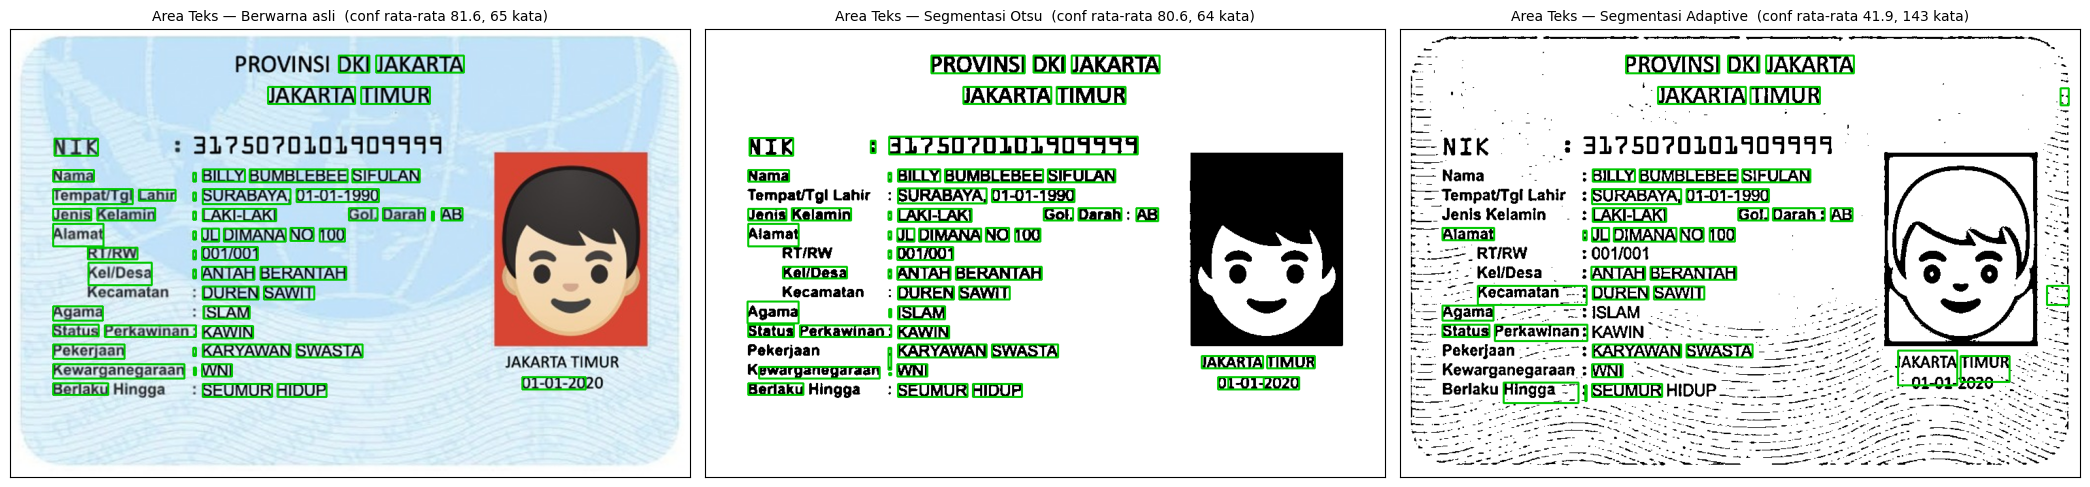

========== BERWARNA ASLI ==========
PROVINSI! DKI JAKARTA
JAKARTA TIMUR

NIK : 31750701019099949
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tg! Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH N 4

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI rei
Berlaku Hingga : SEUMUR HIDUP 01-01-20 

========== SEGMENTASI OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101909999
Nama : BILLY BUMBLEBEE SIFULAN
TempatTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama > ISLAM
Status Perkawinan: KAWIN
Fekerjaan ; KARYAWAN SWASTA JAKARTA TIMUR

ewarganegaraan : WNI 1-01-2020

Berlaku Hingga: SEUMUR HIDUP 01-01- 

========== SEGMENTASI ADAPTIVE ==========
RR tA
ao PROVINSI DKI JAKARTA 3
= . ‘ JAKARTA TIMUR , =
= N

In [33]:
def jalankan_ocr(im_bgr):
    rgb = cv.cvtColor(im_bgr, cv.COLOR_BGR2RGB)
    teks = pytesseract.image_to_string(rgb, lang=LANG, config=CONFIG)
    d = pytesseract.image_to_data(rgb, lang=LANG, config=CONFIG, output_type=pytesseract.Output.DICT)
    kotak = rgb.copy()
    conf_semua = []
    for i in range(len(d['text'])):
        kata = d['text'][i].strip()
        conf = float(d['conf'][i])
        if kata == '' or conf < 0:
            continue
        conf_semua.append(conf)
        if conf > BATAS_CONF:
            x, y, w, h = d['left'][i], d['top'][i], d['width'][i], d['height'][i]
            cv.rectangle(kotak, (x, y), (x + w, y + h), (0, 200, 0), 2)
    rata_conf = float(np.mean(conf_semua)) if conf_semua else 0.0
    return teks, kotak, rata_conf, len(conf_semua)

ocr = {}
for nama, im in masukan.items():
    ocr[nama] = jalankan_ocr(im)

fig, axs = plt.subplots(1, 3, figsize=(21, 5))
for ax, (nama, (teks, kotak, rc, n)) in zip(axs, ocr.items()):
    tampil(ax, kotak, f'Area Teks — {nama}  (conf rata-rata {rc:.1f}, {n} kata)')
plt.tight_layout(); plt.show()

for nama, (teks, _, _, _) in ocr.items():
    print('=' * 10, nama.upper(), '=' * 10)
    print(teks.strip(), '\n')

### D2.4 Tabel 10 item acuan
**Edit daftar `ACUAN` di bawah** agar berisi 10 kata/angka yang terlihat jelas pada **KTP masing-masing anggota** (isi default hanya cocok untuk KTP contoh).
Pilih item yang tidak terlalu pendek (≥ 5 karakter) agar penilaian tidak kebetulan cocok.
Penilaian: **cocok** bila seluruh huruf/angka item sama dengan acuan pada teks hasil OCR; huruf besar/kecil dan spasi awal/akhir diabaikan.
Kolom OCR menampilkan potongan teks hasil OCR yang paling mirip dengan acuan.

In [34]:
ACUAN = [
    'PROVINSI DKI JAKARTA',
    'JAKARTA TIMUR',
    '3175070101909999',
    'BILLY BUMBLEBEE SIFULAN',
    'SURABAYA',
    'LAKI-LAKI',
    'JL DIMANA NO 100',
    'ANTAH BERANTAH',
    'DUREN SAWIT',
    'KARYAWAN SWASTA',
]

def norm(s):
    return re.sub(r'\s+', ' ', s).strip().casefold()

def cocok(item, teks):
    return norm(item) in norm(teks)

def terbaca_mirip(item, teks):
    # potongan teks OCR paling mirip dengan item (untuk ditampilkan di tabel)
    kata = norm(teks).split()
    n = max(1, len(item.split()))
    kandidat = [' '.join(kata[i:i + n]) for i in range(max(1, len(kata) - n + 1))]
    cocokan = difflib.get_close_matches(norm(item), kandidat, n=1, cutoff=0.4)
    return cocokan[0] if cocokan else '(tidak terbaca)'

kolom = {'Berwarna asli': 'OCR citra berwarna', 'Segmentasi Otsu': 'OCR Otsu', 'Segmentasi Adaptive': 'OCR Adaptive'}
baris, skor = [], {m: 0 for m in ocr}
for no, item in enumerate(ACUAN, 1):
    r = {'No.': no, 'Teks sebenarnya': item}
    for m, (teks, _, _, _) in ocr.items():
        ok = cocok(item, teks)
        skor[m] += int(ok)
        r[kolom[m]] = terbaca_mirip(item, teks) + (' ✓' if ok else ' ✗')
    baris.append(r)
tabel = pd.DataFrame(baris)
pd.set_option('display.max_colwidth', 60, 'display.width', 200)
print(tabel.to_string(index=False))

 No.         Teks sebenarnya        OCR citra berwarna                  OCR Otsu              OCR Adaptive
   1    PROVINSI DKI JAKARTA   provinsi! dki jakarta ✗    provinsi dki jakarta ✓    provinsi dki jakarta ✓
   2           JAKARTA TIMUR           jakarta timur ✓           jakarta timur ✓           jakarta timur ✓
   3        3175070101909999       31750701019099949 ✗        3175070101909999 ✓       31750701019099959 ✗
   4 BILLY BUMBLEBEE SIFULAN billy bumblebee sifulan ✓ billy bumblebee sifulan ✓ billy bumblebee sifulan ✓
   5                SURABAYA               surabaya, ✓               surabaya, ✓               surabaya, ✓
   6               LAKI-LAKI               laki-laki ✓               laki-laki ✓               laki-laki ✓
   7        JL DIMANA NO 100        jl dimana no 100 ✓        jl dimana no 100 ✓        jl dimana no 100 ✓
   8          ANTAH BERANTAH          antah berantah ✓          antah berantah ✓          antah berantah ✓
   9             DUREN SAWIT         

### D2.5 Persentase kecocokan & ringkasan

In [35]:
N = len(ACUAN)
ringkasan = pd.DataFrame({
    'Citra masukan OCR': list(ocr.keys()),
    'Item terbaca tepat': [skor[m] for m in ocr],
    'Kecocokan (%)': [skor[m] / N * 100 for m in ocr],
    'Rata-rata confidence': [round(ocr[m][2], 1) for m in ocr],
})
print(ringkasan.to_string(index=False))
print('\nRata-rata confidence dihitung dari semua kata non-kosong yang dikenali (conf >= 0).')

  Citra masukan OCR  Item terbaca tepat  Kecocokan (%)  Rata-rata confidence
      Berwarna asli                   8           80.0                  81.6
    Segmentasi Otsu                  10          100.0                  80.6
Segmentasi Adaptive                   9           90.0                  41.9

Rata-rata confidence dihitung dari semua kata non-kosong yang dikenali (conf >= 0).


### Pertanyaan analisis
Jawaban nomor 1, 2, 3, dan 5 dihasilkan otomatis dari hasil percobaan di atas (angka mengikuti KTP yang dipakai). Nomor 3–4 diberi penjelasan konsep yang perlu Anda cocokkan dengan gambar hasil Anda.

In [36]:
nama_m = list(ocr.keys())
terbaik = max(nama_m, key=lambda m: skor[m])
print('1. Citra masukan paling tepat:', terbaik, f'-> {skor[terbaik]}/{N} item ({skor[terbaik]/N*100:.0f}%).')
print('   Bukti tabel ringkasan:')
for m in nama_m:
    print(f'     - {m:20s}: {skor[m]}/{N} item, conf rata-rata {ocr[m][2]:.1f}')

print('\n2. Contoh kesalahan pembacaan (item acuan -> hasil OCR):')
n_salah = 0
for _, r in tabel.iterrows():
    for m, kol in kolom.items():
        if r[kol].endswith('✗'):
            print(f'     - [{m}] "{r["Teks sebenarnya"]}" terbaca "{r[kol][:-2]}"')
            n_salah += 1
if n_salah == 0:
    print('     (semua item terbaca tepat pada percobaan ini; coba item yang lebih sulit/kecil dari KTP Anda)')

dasar = skor['Berwarna asli']
print('\n3. Dibanding citra berwarna asli (', dasar, '/', N, '):', sep='')
for m in ['Segmentasi Otsu', 'Segmentasi Adaptive']:
    d = skor[m] - dasar
    arah = 'meningkat' if d > 0 else ('menurun' if d < 0 else 'tidak berubah')
    print(f'     - {m}: {arah} ({d:+d} item)')

conf_tinggi = max(nama_m, key=lambda m: ocr[m][2])
print('\n5. Confidence tertinggi:', conf_tinggi, '| Kecocokan tertinggi:', terbaik,
      '->', 'SAMA' if conf_tinggi == terbaik else 'BERBEDA')

1. Citra masukan paling tepat: Segmentasi Otsu -> 10/10 item (100%).
   Bukti tabel ringkasan:
     - Berwarna asli       : 8/10 item, conf rata-rata 81.6
     - Segmentasi Otsu     : 10/10 item, conf rata-rata 80.6
     - Segmentasi Adaptive : 9/10 item, conf rata-rata 41.9

2. Contoh kesalahan pembacaan (item acuan -> hasil OCR):
     - [Berwarna asli] "PROVINSI DKI JAKARTA" terbaca "provinsi! dki jakarta"
     - [Berwarna asli] "3175070101909999" terbaca "31750701019099949"
     - [Segmentasi Adaptive] "3175070101909999" terbaca "31750701019099959"

3. Dibanding citra berwarna asli (8/10):
     - Segmentasi Otsu: meningkat (+2 item)
     - Segmentasi Adaptive: meningkat (+1 item)

5. Confidence tertinggi: Berwarna asli | Kecocokan tertinggi: Segmentasi Otsu -> BERBEDA


**Penjelasan konsep untuk nomor 3, 4, dan 5 (lengkapi dengan angka dari hasil Anda):**

3. **Segmentasi tidak selalu meningkatkan ketepatan OCR.** Tesseract sudah melakukan binarisasi internal (Otsu) sehingga pada citra berwarna yang kontrasnya baik hasil mentahnya sudah bagus. Thresholding membantu bila ada bayangan/pencahayaan tidak merata (Adaptive) atau latar berwarna pekat, tetapi bisa merugikan bila: (a) ambang terlalu tinggi sehingga goresan tipis/huruf kecil hilang, (b) ambang global Otsu dipengaruhi blok gelap besar seperti foto sehingga teks terang terhapus, atau (c) pola latar menjadi bintik noise (terutama Adaptive dengan C kecil) yang dibaca sebagai karakter palsu.
4. **Pengaruh warna/pola latar.** KTP memiliki latar biru bergradasi dengan pola halus (guilloche) dan foto berwarna. Pola ini menurunkan kontras lokal antara huruf dan latar. Pada citra berwarna, huruf kecil di atas pola mudah salah baca (angka tertukar, huruf hilang). Setelah thresholding, latar polos menjadi putih bersih sehingga huruf lebih jelas, namun sisa pola latar dapat tampil sebagai titik/garis halus, dan area foto menjadi blok hitam/pola yang dapat menghasilkan "teks sampah".
5. **Confidence tinggi ≠ kecocokan tinggi.** Confidence adalah keyakinan internal Tesseract pada kata yang *dikenali*, bukan kebenaran terhadap acuan. Citra biner bersih sering memberi confidence tinggi pada kata yang terbaca, tetapi kata yang hilang tidak ikut dihitung dalam rata-rata, sedangkan kecocokan menghitung item yang tidak terbaca sebagai salah. Karena itu keduanya harus dilaporkan bersama (lihat hasil otomatis nomor 5 di atas).